# Land Cover Processing
Load and analyze landcover data and calculate percent forest.

In [1]:
# Imports
import pandas as pd
import xarray as xr
import numpy as np
import os
import matplotlib.pyplot as plt

### Load data
On desktop, environmental vars should be available


In [2]:
# Load SNOTEL sites CSV
snotel_df = pd.read_csv(f"{os.environ['SNOTEL_PATH']}/bcqc_data_v2/SNOTEL_summary.csv")
print(f"Loaded {len(snotel_df)} SNOTEL sites")
snotel_df.head()

Loaded 829 SNOTEL sites


,Num,SNOTEL ID,SNOTEL State,SNOTEL Name,SNOTEL Elev (ft),SNOTEL Lat (),SNOTEL Lon (),Data Starting Date,Data Ending Date,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,1,1000,OR,Annie Springs,6010,42.87,-122.17,9/15/2000,9/30/2018,NaN,NaN,NaN
1,2,1001,AK,Long Lake,850,58.19,-133.83,10/1/1999,9/30/2018,NaN,NaN,NaN
2,3,1003,AK,Mcneil Canyon,1320,59.74,-151.25,10/1/1986,9/30/2018,NaN,NaN,NaN
3,4,1005,CO,Ute Creek,10650,37.61,-105.37,8/15/2000,9/30/2018,NaN,NaN,NaN
4,5,1006,NV,Lewis Peak,7400,40.36,-116.86,8/23/2000,9/30/2018,NaN,NaN,NaN


In [2]:
veg_index = xr.open_dataset(f"{os.environ['GLOBAL_LAND']}/PCT_NAT_PFT_INDEX_2010_1k_c230606.nc")
veg_index


<xarray.Dataset> Size: 7GB
Dimensions:            (lat: 21600, lon: 43200)
Coordinates:
  * lat                (lat) float64 173kB -90.0 -89.99 -89.98 ... 89.99 90.0
  * lon                (lon) float64 346kB -180.0 -180.0 -180.0 ... 180.0 180.0
Data variables:
    PCT_NAT_PFT_INDEX  (lat, lon) float64 7GB ...
Attributes:
    title:          Global 1km Land Surface Parameters for Kilometer Scale Ea...
    version:        1.0
    institution:    Atmospheric Sciences and Global Change Division, Pacific ...
    contact:        Lingcheng Li, lingcheng.li@pnnl.gov; Gautam Bisht, gautam...
    creation_date:  Tue Jan 16 22:48:11 PST 2024

In [ ]:
veg_percent = xr.open_dataset(f"{os.environ['GLOBAL_LAND']}/PCT_NATVEG_2010_1k_c230606.nc")
veg_percent

### Extract SNOTEL values

In [4]:
# Extract data from netCDF for site locations - MEMORY EFFICIENT VERSION
def extract_netcdf_values(sites, variable_name, dataset, lat_col='SNOTEL Lat ()', lon_col='SNOTEL Lon ()'):
    """
    Extract values from a netCDF dataset at specified site locations without loading full array.
    
    Parameters:
    -----------
    sites : pd.DataFrame
        Dataframe containing site information with latitude and longitude columns
    variable_name : str
        Name of the variable to extract from the netCDF file
    dataset : xarray.Dataset
        Loaded xarray Dataset
    lat_col : str, optional
        Name of the latitude column in the sites dataframe (default: 'SNOTEL Lat ()')
    lon_col : str, optional
        Name of the longitude column in the sites dataframe (default: 'SNOTEL Lon ()')
    
    Returns:
    --------
    np.array
        Array of extracted values for each site
    """
    # Get the coordinate arrays from the dataset (these are small, just 1D arrays)
    lats_grid = dataset.lat.values
    lons_grid = dataset.lon.values
    
    # Get site coordinates
    site_lats = sites[lat_col].values
    site_lons = sites[lon_col].values
    
    # Find nearest indices using searchsorted (much faster than xarray's method='nearest')
    lat_indices = np.searchsorted(lats_grid, site_lats)
    lon_indices = np.searchsorted(lons_grid, site_lons)
    
    # Clip indices to valid range
    lat_indices = np.clip(lat_indices, 0, len(lats_grid) - 1)
    lon_indices = np.clip(lon_indices, 0, len(lons_grid) - 1)
    
    # For each point, check if the previous index is actually closer
    for i in range(len(lat_indices)):
        if lat_indices[i] > 0:
            if abs(lats_grid[lat_indices[i] - 1] - site_lats[i]) < abs(lats_grid[lat_indices[i]] - site_lats[i]):
                lat_indices[i] -= 1
        if lon_indices[i] > 0:
            if abs(lons_grid[lon_indices[i] - 1] - site_lons[i]) < abs(lons_grid[lon_indices[i]] - site_lons[i]):
                lon_indices[i] -= 1
    
    # Extract values one at a time to avoid loading full array into memory
    values = np.zeros(len(site_lats))
    for i in range(len(site_lats)):
        # Use isel to select specific indices - this only loads that one point
        values[i] = dataset[variable_name].isel(lat=lat_indices[i], lon=lon_indices[i]).values
    
    return values

In [5]:
# Extract values for SNOTEL sites from both datasets
pft_index_values = extract_netcdf_values(snotel_df, 'PCT_NAT_PFT_INDEX', veg_index)
pct_natveg_values = extract_netcdf_values(snotel_df, 'PCT_NATVEG', veg_percent)

# Add to dataframe
snotel_df['PFT_INDEX'] = pft_index_values
snotel_df['PCT_NATVEG'] = pct_natveg_values

print(f"Extracted values for {len(snotel_df)} sites")
print(f"PFT Index range: {np.nanmin(pft_index_values):.2f} - {np.nanmax(pft_index_values):.2f}")
print(f"Percent Native Veg range: {np.nanmin(pct_natveg_values):.2f} - {np.nanmax(pct_natveg_values):.2f}")
snotel_df[['SNOTEL Name', 'SNOTEL Lat ()', 'SNOTEL Lon ()', 'PFT_INDEX', 'PCT_NATVEG']].head(10)

Extracted values for 829 sites
PFT Index range: 0.00 - 15.00
Percent Native Veg range: 0.00 - 100.00


,SNOTEL Name,SNOTEL Lat (),SNOTEL Lon (),PFT_INDEX,PCT_NATVEG
0,Annie Springs,42.87,-122.17,2.0,100.0
1,Long Lake,58.19,-133.83,12.0,100.0
2,Mcneil Canyon,59.74,-151.25,8.0,100.0
3,Ute Creek,37.61,-105.37,2.0,100.0
4,Lewis Peak,40.36,-116.86,13.0,100.0
5,Onion Park,46.91,-110.85,2.0,100.0
6,Stringer Creek,46.93,-110.90,2.0,100.0
7,Crazyman Flat,42.64,-120.95,2.0,100.0
8,MF Nooksack,48.82,-121.93,2.0,100.0
9,Swift Creek,46.16,-122.18,12.0,100.0


### Create maps of extracted values

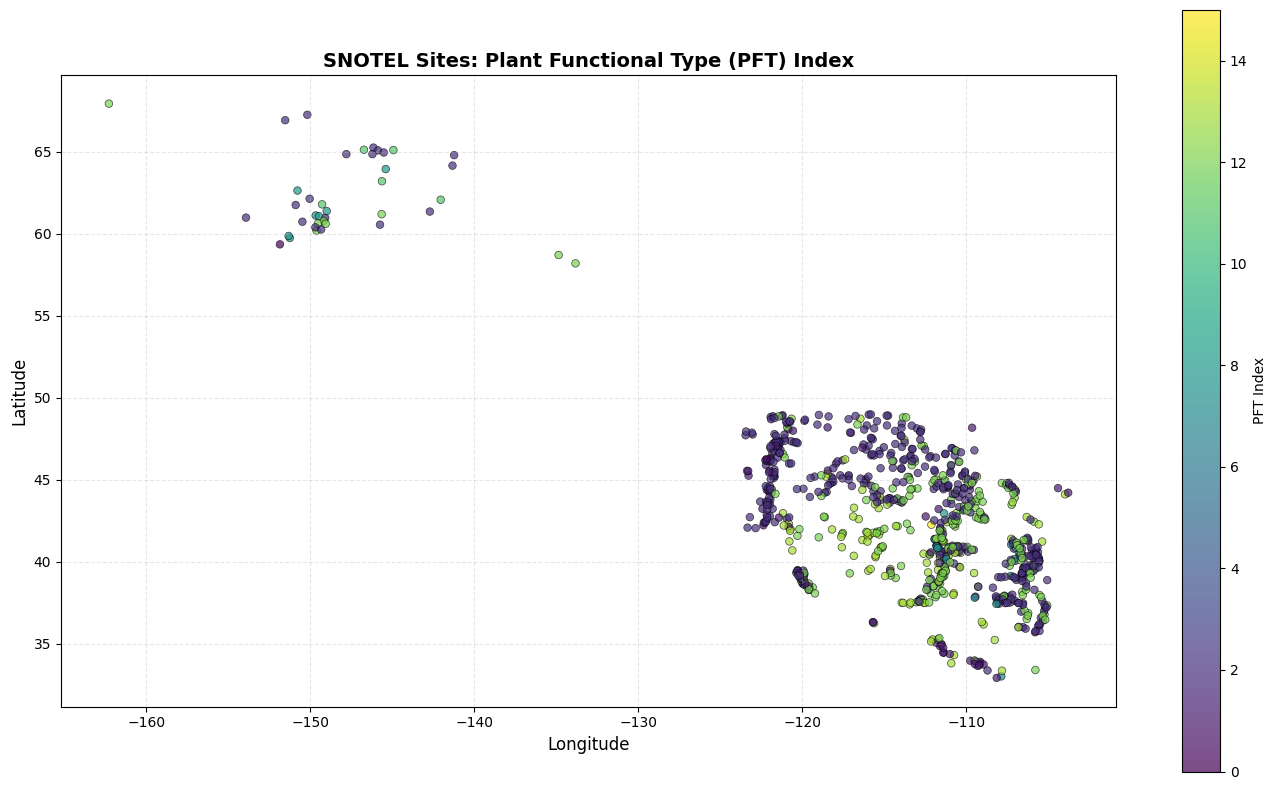

Number of sites plotted: 829


In [6]:
# Plot 1: PFT Index values
fig, ax = plt.subplots(figsize=(14, 8))

# Create scatter plot colored by PFT_INDEX values
scatter = ax.scatter(snotel_df['SNOTEL Lon ()'], 
                     snotel_df['SNOTEL Lat ()'], 
                     c=snotel_df['PFT_INDEX'], 
                     cmap='viridis', 
                     s=30, 
                     alpha=0.7,
                     edgecolors='black',
                     linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, label='PFT Index')

# Formatting
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.set_title('SNOTEL Sites: Plant Functional Type (PFT) Index', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.show()

print(f"Number of sites plotted: {len(snotel_df)}")

In [7]:
snotel_df[['SNOTEL Name','SNOTEL Lat ()', 'SNOTEL Lon ()', 'PFT_INDEX', 'PCT_NATVEG']].to_csv(
    '../site_characteristics/snotel_veg.csv')